In [143]:
import os
import pandas as pd
from urllib import request
from astroquery.gaia import Gaia
from kineamtics_and_dynamics import UVW, gal_population, compute_orbit_params

In [144]:
import numpy as np
import joblib

try:
    nea_gaia_with_kinematics
except NameError:
    nea_gaia_with_kinematics = pd.read_csv('nea_gaia_full_table.csv', low_memory=False)

feh_model = joblib.load('models/best_lgbm_fe.joblib')
FEH_FEATURES = list(feh_model.feature_name_)
FEH_FEATURES


['zmax',
 'rperi',
 'P_gal',
 'eccentricity',
 'rapo',
 'V_lsr',
 'W_lsr',
 'UVW_lsr',
 'U_lsr']

In [145]:
nea_gaia_with_kinematics.columns

Index(['pl_name', 'pl_letter', 'hostname', 'hd_name', 'hip_name', 'tic_id',
       'gaia_dr2_id', 'gaia_dr3_id', 'default_flag', 'pl_refname',
       ...
       'mh_gspphot', 'mh_gspspec', 'U_lsr', 'V_lsr', 'W_lsr', 'P_gal', 'rapo',
       'rperi', 'eccentricity', 'zmax'],
      dtype='object', length=376)

In [146]:
nea_feh_predictions = nea_gaia_with_kinematics.copy()
nea_feh_predictions['UVW_lsr'] = np.sqrt(
    nea_feh_predictions['U_lsr']**2 + nea_feh_predictions['V_lsr']**2 + nea_feh_predictions['W_lsr']**2
)

X_feh = nea_feh_predictions[FEH_FEATURES].copy()
valid_feh_rows = X_feh.notna().all(axis=1)

nea_feh_predictions['fe_h_pred'] = np.nan
nea_feh_predictions.loc[valid_feh_rows, 'fe_h_pred'] = feh_model.predict(X_feh.loc[valid_feh_rows])

print(f"Rows with complete features for [Fe/H] prediction: {valid_feh_rows.sum()} / {len(nea_feh_predictions)}")
nea_feh_predictions.to_csv('nea_gaia_with_predicted_feh.csv', index=False)
nea_feh_predictions[['pl_name', 'hostname', 'source_id', 'fe_h_pred'] + FEH_FEATURES].head()


Rows with complete features for [Fe/H] prediction: 4410 / 5774


,pl_name,hostname,source_id,fe_h_pred,zmax,rperi,P_gal,eccentricity,rapo,V_lsr,W_lsr,UVW_lsr,U_lsr
0,HD 114783 b,HD 114783,3684934540986187776,-0.038832,0.047395,8.098465,99.2,0.049889,8.948943,9.381666,-1.582349,10.629722,4.740412
1,HD 12661 c,HD 12661,105332908999068032,-0.030557,0.069776,6.056471,97.6,0.224308,9.559196,-17.259945,4.685592,65.590824,-63.105433
2,HD 27894 c,HD 27894,4678605152248591488,-0.099633,0.640797,4.282972,47.1,0.336960,8.636223,-61.441874,-34.696715,88.733682,53.802419
3,TOI-4010 b,TOI-4010,525352325110310400,-0.010690,0.090918,7.479925,99.1,0.080746,8.793972,-3.333874,-5.871674,20.683912,19.550779
4,HD 12661 b,HD 12661,105332908999068032,-0.030557,0.069776,6.056471,97.6,0.224308,9.559196,-17.259945,4.685592,65.590824,-63.105433


In [147]:
abundance_models = {
    'mg_h_pred': joblib.load('models/lgbm_model_mg_h.joblib'),
    'si_h_pred': joblib.load('models/lgbm_model_si_h.joblib'),
    'o_h_pred': joblib.load('models/lgbm_model_o_h.joblib'),
    'c_h_pred': joblib.load('models/lgbm_model_c_h.joblib'),
}

ABUNDANCE_FEATURES = list(next(iter(abundance_models.values())).feature_name_)
ABUNDANCE_FEATURES


['U_lsr',
 'V_lsr',
 'W_lsr',
 'P_gal',
 'rapo',
 'rperi',
 'eccentricity',
 'zmax',
 'fe_h']

In [148]:
nea_abundance_predictions = nea_feh_predictions.copy()
nea_abundance_predictions['fe_h_input_abund'] = nea_abundance_predictions['st_met']
nea_abundance_predictions['fe_h'] = nea_abundance_predictions['fe_h_input_abund']

X_abund = nea_abundance_predictions[ABUNDANCE_FEATURES].copy()
valid_abundance_rows = X_abund.notna().all(axis=1)

for output_column, model in abundance_models.items():
    nea_abundance_predictions[output_column] = np.nan
    nea_abundance_predictions.loc[valid_abundance_rows, output_column] = model.predict(
        X_abund.loc[valid_abundance_rows]
    )

print(f"Rows with complete features for abundance prediction: {valid_abundance_rows.sum()} / {len(nea_abundance_predictions)}")
nea_abundance_predictions.to_csv('nea_gaia_with_predicted_abundances.csv', index=False)
nea_abundance_predictions[
    ['pl_name', 'hostname', 'source_id', 'st_met', 'fe_h_input_abund', 'mg_h_pred', 'si_h_pred', 'o_h_pred', 'c_h_pred']
].head()


Rows with complete features for abundance prediction: 3343 / 5774


,pl_name,hostname,source_id,st_met,fe_h_input_abund,mg_h_pred,si_h_pred,o_h_pred,c_h_pred
0,HD 114783 b,HD 114783,3684934540986187776,0.21,0.21,0.217309,0.216107,0.234389,0.118581
1,HD 12661 c,HD 12661,105332908999068032,0.36,0.36,0.391604,0.363522,0.414643,0.338429
2,HD 27894 c,HD 27894,4678605152248591488,0.30,0.30,0.340008,0.308428,0.343918,0.267504
3,TOI-4010 b,TOI-4010,525352325110310400,0.37,0.37,0.412399,0.372719,0.409331,0.325546
4,HD 12661 b,HD 12661,105332908999068032,0.36,0.36,0.391604,0.363522,0.414643,0.338429


In [149]:
import matplotlib.pyplot as plt
from pathlib import Path

try:
    nea_abundance_predictions
except NameError:
    nea_abundance_predictions = pd.read_csv('nea_gaia_with_predicted_abundances.csv', low_memory=False)

comparison_dir = Path('figures/nea_metallicity_comparison')
comparison_dir.mkdir(parents=True, exist_ok=True)

nea_star_level = nea_abundance_predictions.sort_values('source_id').drop_duplicates(subset='source_id').copy()
print(f'Total rows: {len(nea_abundance_predictions)}')
print(f'Unique stars used once: {len(nea_star_level)}')


Total rows: 5774
Unique stars used once: 4234


In [150]:
def plot_feh_comparison(df, true_column, pretty_label, out_prefix):
    comp = df[['source_id', 'fe_h_pred', true_column]].dropna().copy()
    comp['residual'] = comp[true_column] - comp['fe_h_pred']

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(comp[true_column], comp['residual'], s=18, alpha=0.65)
    ax.axhline(0.0, color='black', linestyle='--', linewidth=1)
    ax.set_xlabel(pretty_label)
    ax.set_ylabel('Residual (true - pred) [dex]') 

    plt.tight_layout()
    fig.savefig(comparison_dir / f'{out_prefix}_comparison.png', dpi=200, bbox_inches='tight')
    plt.show()

    return pd.Series({
        'n_stars': len(comp),
        'mean_residual': comp['residual'].mean(),
        'std_residual': comp['residual'].std(),
        'mae': comp['residual'].abs().mean(),
    })


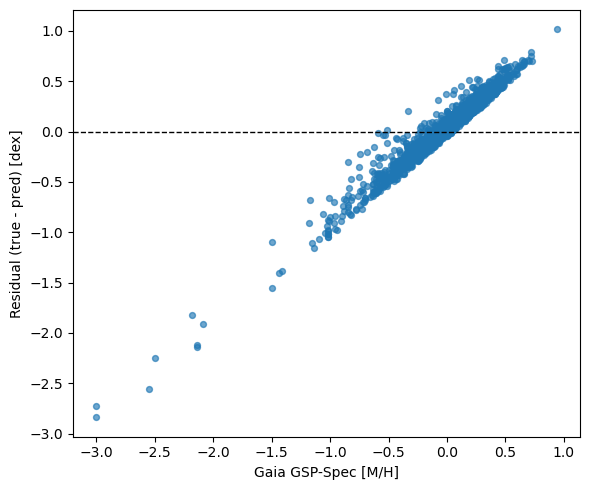

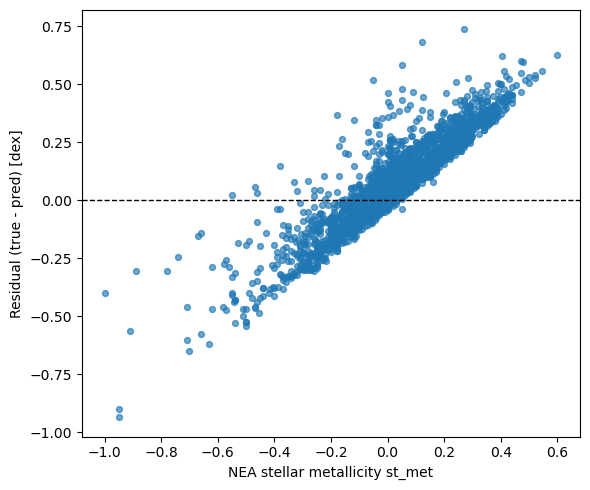

,n_stars,mean_residual,std_residual,mae
mh_gspspec,1820.0,0.018144,0.342097,0.246632
st_met,2578.0,0.082155,0.183149,0.157100


In [151]:
comparison_summary = pd.DataFrame({
    'mh_gspspec': plot_feh_comparison(nea_star_level, 'mh_gspspec', 'Gaia GSP-Spec [M/H]', 'feh_vs_mh_gspphot'),
    'st_met': plot_feh_comparison(nea_star_level, 'st_met', 'NEA stellar metallicity st_met', 'feh_vs_st_met'),
}).T

comparison_summary


In [152]:
def plot_reference_comparison(df, x_column, y_column, x_label, y_label, out_prefix):
    comp = df[['source_id', x_column, y_column]].dropna().copy()
    comp['residual'] = comp[x_column] - comp[y_column]

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(comp[x_column], comp['residual'], s=18, alpha=0.65)
    ax.axhline(0.0, color='black', linestyle='--', linewidth=1)
    ax.set_xlabel(x_label)
    ax.set_ylabel(f'Residual: {x_label} - {y_label}')

    plt.tight_layout()
    fig.savefig(comparison_dir / f'{out_prefix}_comparison.png', dpi=200, bbox_inches='tight')
    plt.show()

    return pd.Series({
        'n_stars': len(comp),
        'mean_residual': comp['residual'].mean(),
        'std_residual': comp['residual'].std(),
        'mae': comp['residual'].abs().mean(),
    })


In [153]:
SWEETCAT_URL = 'https://sweetcat.iastro.pt/catalog/SWEETCAT_Dataframe.csv'

sweetcat = pd.read_csv(SWEETCAT_URL, low_memory=False)
sweetcat['source_id'] = pd.to_numeric(sweetcat['gaia_dr3'], errors='coerce').astype('Int64').astype('string')
sweetcat = sweetcat.rename(columns={
    '[Fe/H]': 'fe_h_sweetcat',
    'e[Fe/H]': 'e_fe_h_sweetcat',
    'Name': 'sweetcat_name',
})
sweetcat = sweetcat[['source_id', 'sweetcat_name', 'fe_h_sweetcat', 'e_fe_h_sweetcat', 'SWFlag']].dropna(subset=['source_id'])
sweetcat = sweetcat.drop_duplicates(subset='source_id').copy()
sweetcat = sweetcat[sweetcat.SWFlag == 1].copy()

print(f'SWEET-Cat rows with Gaia DR3 IDs: {len(sweetcat)}')
sweetcat.head()


SWEET-Cat rows with Gaia DR3 IDs: 1256


,source_id,sweetcat_name,fe_h_sweetcat,e_fe_h_sweetcat,SWFlag
0,3946945413106333696,11 Com,-0.26,0.02,1
1,1696798367260229376,11 UMi,-0.05,0.04,1
2,1920113512486282240,14 And,-0.28,0.03,1
3,1385293808145621504,14 Her,0.37,0.04,1
4,2135550755683407232,16 Cyg B,0.09,0.02,1


In [154]:
nea_star_level['source_id'] = nea_star_level['source_id'].astype('string')
nea_sweetcat = nea_star_level.merge(sweetcat, on='source_id', how='left')

print(f'Unique stars in NEA table: {len(nea_star_level)}')
print(f'Stars matched to SWEET-Cat: {nea_sweetcat["fe_h_sweetcat"].notna().sum()}')
nea_sweetcat[['pl_name', 'hostname', 'source_id', 'fe_h_pred', 'fe_h_sweetcat', 'e_fe_h_sweetcat']].head()


Unique stars in NEA table: 4234
Stars matched to SWEET-Cat: 1196


,pl_name,hostname,source_id,fe_h_pred,fe_h_sweetcat,e_fe_h_sweetcat
0,CD Cet b,CD Cet,3179036008830848,-0.017246,-0.110,0.130
1,TOI-2537 c,TOI-2537,12320268307415552,-0.040414,NaN,NaN
2,HD 14787 b,HD 14787,24570756281835392,-0.131558,-0.068,0.019
3,HD 20329 b,HD 20329,30398648945512960,-0.161817,NaN,NaN
4,Teegarden's Star d,Teegarden's Star,35227046884571776,NaN,NaN,NaN


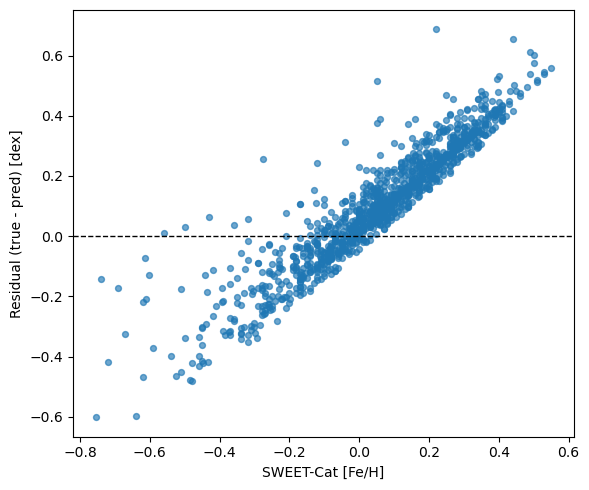

,n_stars,mean_residual,std_residual,mae
sweetcat_feh,1156.0,0.105073,0.197749,0.182581


In [155]:
sweetcat_comparison_summary = pd.DataFrame({
    'sweetcat_feh': plot_feh_comparison(
        nea_sweetcat,
        'fe_h_sweetcat',
        'SWEET-Cat [Fe/H]',
        'feh_vs_sweetcat',
    )
}).T

sweetcat_comparison_summary


In [156]:
nea_sweetcat['fe_h_sweetcat'].describe()

count    1196.000000
mean        0.053176
std         0.217228
min        -0.755000
25%        -0.080000
50%         0.070000
75%         0.210000
max         0.550000
Name: fe_h_sweetcat, dtype: float64